# Check diagnostics

Check sampler errors and chain behavior before interpreting posterior estimates.

In [1]:
import jax.numpy as jnp
import numpy as np
import tensorflow_probability.substrates.jax.bijectors as tfb
import tensorflow_probability.substrates.jax.distributions as tfd

import liesel.goose as gs
import liesel.model as lsl

## Prepare the example

These examples require the regression `model` and sampling `results` from
{doc}`tutorials/md/01c-transform`, with `sigma_sq` included in the stored draws.

In [2]:
# Python cell fragment: imports are visible in each guide.
# Simulate regression observations.
rng = np.random.default_rng(42)
n = 500
true_beta = np.array([1.0, 2.0])
true_sigma = 1.0
x = rng.uniform(size=n)
X_mat = np.column_stack([np.ones(n), x])
y_vec = X_mat @ true_beta + rng.normal(scale=true_sigma, size=n)

# Define the priors.
beta = lsl.Var.new_param(
    jnp.zeros(2),
    dist=lsl.Dist(tfd.Normal, 0.0, 5.0),
    name="beta",
)
sigma_sq = lsl.Var.new_param(
    1.0,
    dist=lsl.Dist(tfd.InverseGamma, concentration=3.0, scale=2.0),
    name="sigma_sq",
)

# Connect the parameters to the observations.
sigma = lsl.Var.new_calc(jnp.sqrt, sigma_sq, name="sigma")
X = lsl.Var.new_obs(X_mat, name="X")
mu = lsl.Var.new_calc(jnp.dot, X, beta, name="mu")
y = lsl.Var.new_obs(
    y_vec,
    dist=lsl.Dist(tfd.Normal, mu, sigma),
    name="y",
)

sigma_sq.biject(tfb.Exp(), name="log_sigma_sq")
log_sigma_sq = sigma_sq.bijected_var

joint = gs.MCMCSpec(
    gs.NUTSKernel,
    kernel_group="regression",
    jitter_dist=tfd.Normal(0.0, 0.2),
)
beta.inference = joint
log_sigma_sq.inference = joint
model = lsl.Model(y)


In [3]:
results = gs.LieselMCMC(model).run_for_epochs(
    seed=1,
    num_chains=4,
    adaptation=1000,
    posterior=1000,
    positions_included=["sigma_sq"],
    show_progress=False,
)

liesel.goose.engine - INFO - Initializing kernels...


liesel.goose.engine - INFO - Done


liesel.goose.engine - INFO - Finished warmup


## Read the summary

In [4]:
summary = gs.Summary(results, selected=["beta", "sigma_sq"])

In [5]:
summary.to_dataframe().set_index("var_fqn")[
    ["mean", "sd", "mcse_mean", "ess_bulk", "rhat"]
].round(3)

,mean,sd,mcse_mean,ess_bulk,rhat
var_fqn,,,,,
beta[0],0.990,0.091,0.002,1444.217,1.004
beta[1],1.899,0.158,0.004,1432.583,1.005
sigma_sq,1.039,0.065,0.001,2172.744,1.003


In [6]:
summary.aggregate_diagnostics().round(3)

,ess_bulk,ess_tail,rhat,aggregated_by
parameter,,,,
beta,1432.583,1540.084,1.005,min (ess); max (rhat)
sigma_sq,2172.744,1970.398,1.003,min (ess); max (rhat)


In [7]:
summary.error_df().reset_index().filter(["error_msg", "phase", "count"])

,error_msg,phase,count
0,divergent transition,warmup,50
1,divergent transition,posterior,0


{meth}`aggregate_diagnostics() <liesel.goose.SamplesSummary.aggregate_diagnostics>` reports the smallest bulk/tail ESS and the largest
R-hat within each parameter variable. This keeps a coefficient vector's worst
diagnostics visible without printing every element.

* **R-hat** compares variation within and between chains.
* **Bulk and tail ESS** describe how much information the dependent draws
  contain about the center and tails.
* **MCSE** measures Monte Carlo uncertainty in an estimated summary, not the
  posterior uncertainty represented by its standard deviation or interval.

As a practical check, aim for R-hat below 1.01 across several chains and enough
ESS for the summaries you need. Compare MCSE with the precision your analysis
requires. See the [Stan diagnostic guidance](https://mc-stan.org/learn-stan/diagnostics-warnings.html) for thresholds and
their limitations. Good diagnostics are evidence, not proof of convergence.

## Inspect the paths

The {doc}`first tutorial <tutorials/md/01c-transform>` shows trace plots
of all three estimated quantities. Goose also provides
{func}`~liesel.goose.plot_trace` and {func}`~liesel.goose.plot_cor`
for quick trace and autocorrelation plots.

Look for drift, chains occupying different regions, and long stretches with
little movement. Autocorrelation helps identify slow exploration.
{func}`~liesel.goose.plot_pairs` can reveal dependence between parameters;
{func}`~liesel.goose.plot_param` combines several views of one parameter.

## Investigate problems

| Symptom | Next check |
| --- | --- |
| Non-finite starting density or acceptance probability | Inspect {meth}`model.diagnose() <liesel.model.Model.diagnose>`, parameter support, calculations, and starting values. |
| Divergent HMC/NUTS transitions | Investigate posterior geometry, scaling, and parameterization; a higher target acceptance may help but is not a general repair. |
| Maximum NUTS tree depth | Check mixing and parameter dependence. Longer trajectories cost more, so investigate before increasing the limit. |
| Poor chain overlap or high R-hat | Inspect the affected parameters, starting regions, and possible separate modes. |
| Small ESS or large MCSE | Inspect autocorrelation and blocking. Once exploration is satisfactory, more posterior draws can improve precision. |

Divergences can indicate biased exploration; a tree-depth limit is primarily an
efficiency concern. Kernel error codes differ, so use their accompanying
messages rather than comparing numeric codes across methods.

Scatter, pair, trace, and density plots automatically highlight draws associated with
divergent HMC or NUTS transitions when usable diagnostics are available:

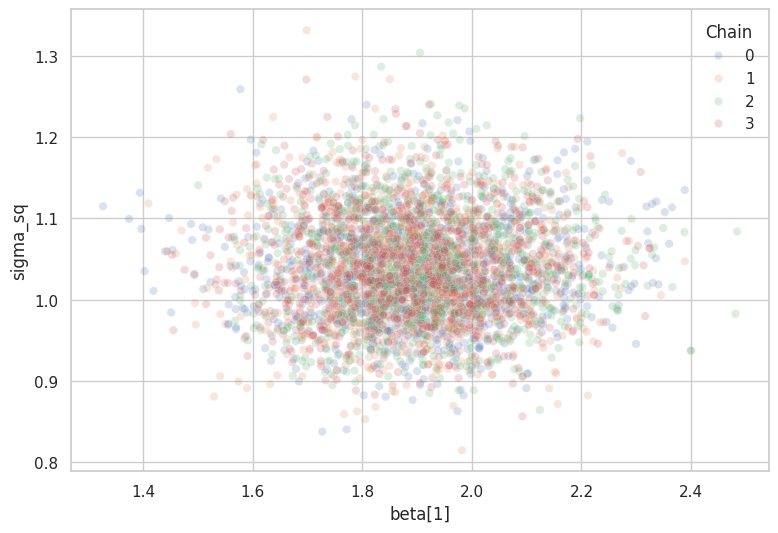

In [8]:
gs.plot_scatter(
    results,
    params=["beta", "sigma_sq"],
    param_indices=(1, 0),
)

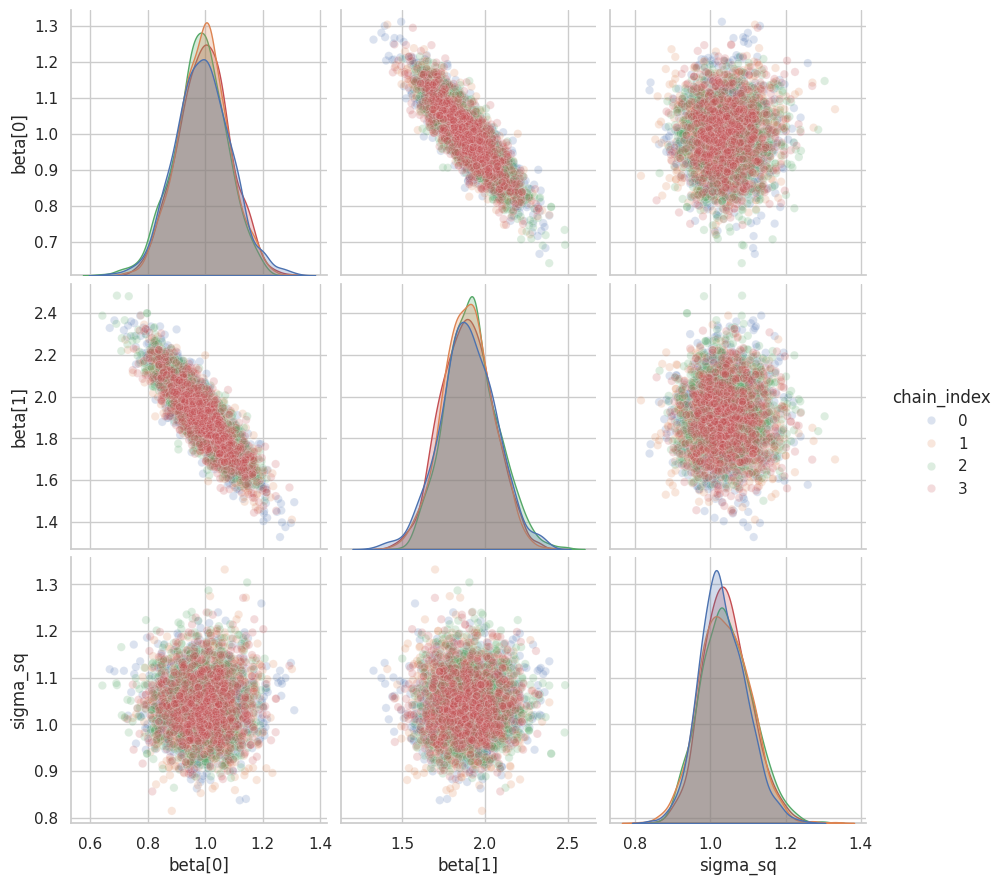

In [9]:
gs.plot_pairs(
    results,
    params=["beta", "sigma_sq"],
)

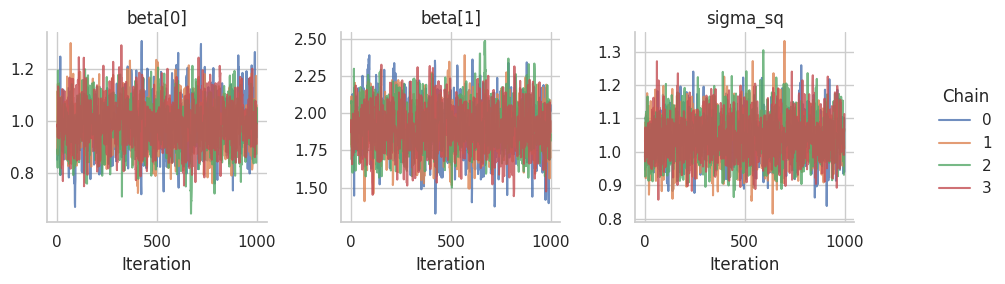

In [10]:
gs.plot_trace(results, params=["beta", "sigma_sq"]);

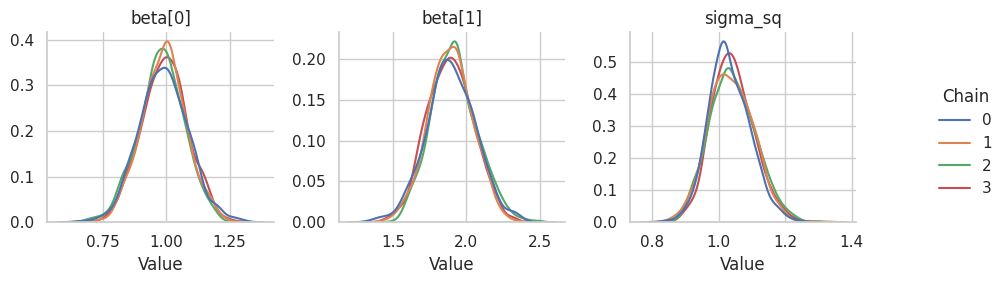

In [11]:
gs.plot_density(results, params=["beta", "sigma_sq"]);

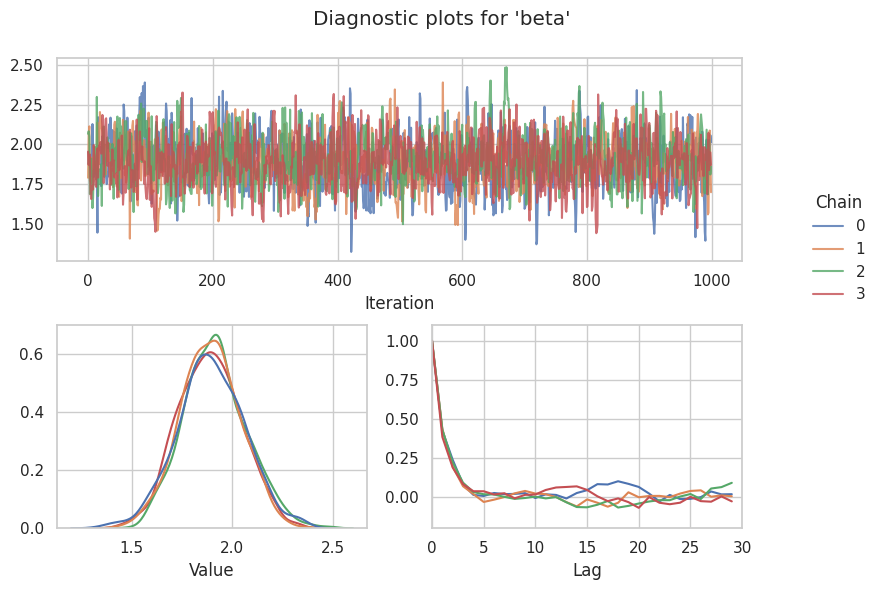

In [12]:
gs.plot_param(results, "beta", param_index=1)

By default, a scatter panel marks a draw if an HMC/NUTS kernel updating **either
plotted parameter** diverged. Each pair-plot diagonal shows a combined red rug
only for divergences from the kernel updating that parameter. Components of a
jointly updated vector share their kernel's divergence flags. NUTS transitions
that also reached maximum tree depth are included. The chain-colored densities
or histograms still use all retained draws, and the rug also works when plotting
a single parameter. A shared “Divergent” legend entry appears only when at least
one displayed panel has marked draws.

Trace panels show a combined red rug along the bottom, marking the iteration
indices of retained divergent draws from the kernel updating that parameter.
The rug pools the displayed chains; pass `chain_indices` to investigate a
particular chain. It helps locate clusters of divergences in time while preserving
the chain-colored trace lines and axis limits.

In {func}`~liesel.goose.plot_density`, the rug marks parameter values of divergent
draws, helping locate affected regions of the posterior. The chain-colored KDE
curves still use all retained draws. In {func}`~liesel.goose.plot_param`, both the
trace and density panels receive rugs; the autocorrelation panel is unchanged.

To mark draws whenever **any HMC/NUTS kernel** diverged, including kernels that
update unplotted parameters, also pass `divergence_scope="any"`. This applies the
same flags to every scatter panel, diagonal rug, trace rug, and density rug. The default is
`divergence_scope="parameter"`.

The default `highlight_divergences="auto"` uses diagnostics from a
{class}`SamplingResults <liesel.goose.SamplingResults>` object. Raw sample
dictionaries and results known to contain no HMC/NUTS kernels plot normally
without markers. If diagnostics or the required kernel mapping are missing,
incomplete, or misaligned, automatic highlighting emits a warning and plots
without markers; this does not mean that there were zero divergences.
Use `highlight_divergences=True` to require highlighting and raise an error
when it cannot be provided, or `False` to disable it and skip diagnostic checks.

Parameter scope requires the results' mapping from parameters to kernels.
Parameters absent from that mapping, such as stored derived quantities, and
parameters updated by other kernel types contribute no divergence flags in this
scope. Use `"any"` to inspect them against all HMC/NUTS divergences; this scope
does not require the mapping. Chain selection and thinning are respected. With
`include_warmup=True` in scatter, pair, or trace plots, warmup draws are included,
but initial values have no transition diagnostic and receive no marker.
Divergences in discarded iterations
are not displayed. Marked points are stored draws after the full kernel sequence,
not intermediate locations along a divergent trajectory.
{func}`~liesel.goose.plot_param` and {func}`~liesel.goose.plot_density` use posterior
draws only.

## Check acceptance

In [13]:
summary.acceptance_prob_df().reset_index()[
    ["phase", "acceptance_probability", "position_moved"]
].round(3)

,phase,acceptance_probability,position_moved
0,posterior,0.881,NaN
1,warmup,0.791,NaN


The table separates acceptance probabilities from the fraction of transitions
that moved. NUTS does not report a move indicator, so its summary shows `NaN`.
For kernels that report movement, `position_moved` is the fraction of
transitions that changed the position.

High acceptance alone does not establish good mixing, and an exact Gibbs
update does not need an accept/reject step.

To investigate adaptation, {ref}`record kernel states <goose-record-tuning>`
during sampling.